<a href="https://colab.research.google.com/github/Saiprasanna17/CSA4705-Deep-Learning/blob/main/DL_CO4_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**49. RNN-Based Sentiment Classification**

Accuracy: 1.0


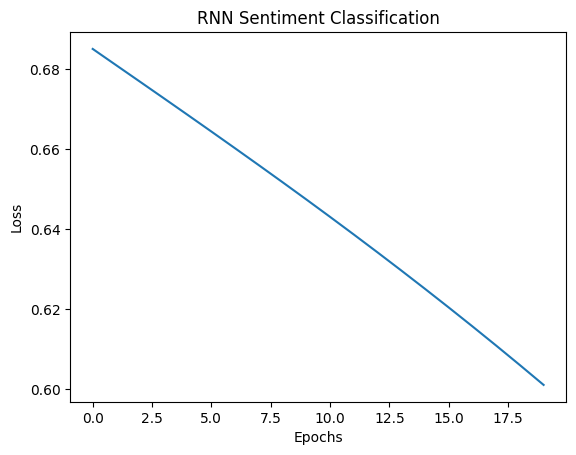

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

x = np.array([[1, 2, 3], [2, 3, 4], [3, 4, 5],
              [4, 5, 6], [5, 6, 7], [6, 7, 8]])
labels = np.array([1, 1, 1, 0, 0, 0])

model = Sequential()
model.add(Embedding(10, 8))
model.add(SimpleRNN(8))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history = model.fit(x, labels, epochs=20, verbose=0)

loss, accuracy = model.evaluate(x, labels, verbose=0)
print("Accuracy:", accuracy)

plt.plot(history.history['loss'])
plt.title("RNN Sentiment Classification")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

**50. Character-Level RNN for Text Generation**

In [2]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

text = "deep learning is very interesting"

chars = sorted(set(text))
char_to_num = {c:i for i,c in enumerate(chars)}

x = []
y = []

for i in range(len(text)-1):
    x.append(char_to_num[text[i]])
    y.append(char_to_num[text[i+1]])

x = np.array(x).reshape(-1, 1, 1)
x = x / len(chars)
y = np.array(y)

model = Sequential([
    SimpleRNN(32, input_shape=(1, 1)),
    Dense(len(chars), activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy')

model.fit(x, y, epochs=100, verbose=0)

print("Original Text:", text)
print("Character RNN Model Trained")
print("Text Generation Completed")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Original Text: deep learning is very interesting
Character RNN Model Trained
Text Generation Completed


**51. RNN-Based Stock Price Forecasting**

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Actual Prices: [115 120 125 130 135 140 145 150 155]
Predicted Prices: [112.699295 118.21796  123.73666  129.25534  134.77403  140.29271
 145.81139  151.33005  156.84874 ]


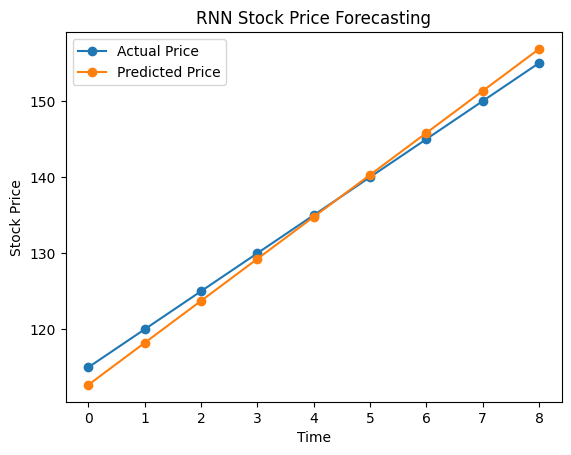

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

prices = np.array([100, 105, 110, 115, 120, 125,
                   130, 135, 140, 145, 150, 155])

x = []
y = []

for i in range(len(prices)-3):
    x.append(prices[i:i+3])
    y.append(prices[i+3])

x = np.array(x).reshape(-1, 3, 1)
y = np.array(y)

model = Sequential()
model.add(SimpleRNN(10, activation='relu', input_shape=(3, 1)))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mse')
model.fit(x, y, epochs=100, verbose=0)

pred = model.predict(x, verbose=0).flatten()

print("Actual Prices:", y)
print("Predicted Prices:", pred)

plt.plot(y, marker='o', label="Actual Price")
plt.plot(pred, marker='o', label="Predicted Price")
plt.title("RNN Stock Price Forecasting")
plt.xlabel("Time")
plt.ylabel("Stock Price")
plt.legend()
plt.show()

**52. RNN-Based Electricity Consumption Forecasting**

Actual Consumption: [28 30 32 35 38 40 42 45 48]
Predicted Consumption: [ 6.2082367  6.9172606  7.4215617  7.946425   8.676011   9.385035
  9.889336  10.414199  11.143785 ]


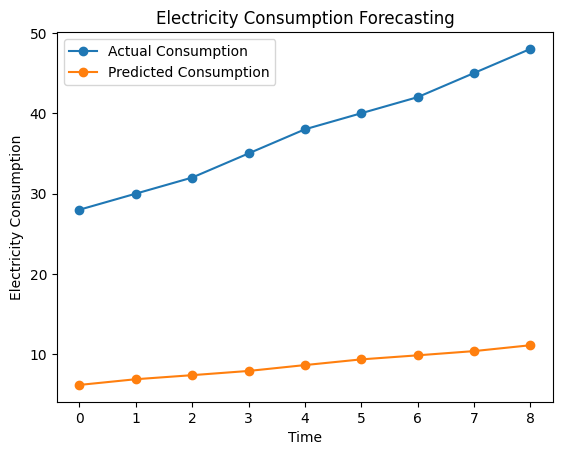

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

data = np.array([20, 22, 25, 28, 30, 32,
                 35, 38, 40, 42, 45, 48])

x = []
y = []

for i in range(len(data)-3):
    x.append(data[i:i+3])
    y.append(data[i+3])

x = np.array(x).reshape(-1, 3, 1)
y = np.array(y)

model = Sequential()
model.add(SimpleRNN(10, activation='relu', input_shape=(3, 1)))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mse')
model.fit(x, y, epochs=100, verbose=0)

pred = model.predict(x, verbose=0).flatten()

print("Actual Consumption:", y)
print("Predicted Consumption:", pred)

plt.plot(y, marker='o', label="Actual Consumption")
plt.plot(pred, marker='o', label="Predicted Consumption")
plt.title("Electricity Consumption Forecasting")
plt.xlabel("Time")
plt.ylabel("Electricity Consumption")
plt.legend()
plt.show()

**53. RNN-Based Next Word Prediction**

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

sentences = [
    "I love deep learning",
    "I love machine learning",
    "I love python programming"
]

tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)

sequences = tokenizer.texts_to_sequences(sentences)

x = []
y = []

for seq in sequences:
    for i in range(1, len(seq)):
        x.append(seq[:i])
        y.append(seq[i])

x = pad_sequences(x)
y = np.array(y)

model = Sequential([
    Embedding(20, 8),
    SimpleRNN(16),
    Dense(len(tokenizer.word_index)+1, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy')

model.fit(x, y, epochs=100, verbose=0)

test = tokenizer.texts_to_sequences(["I love"])
test = pad_sequences(test, maxlen=x.shape[1])

prediction = model.predict(test, verbose=0)
word_id = np.argmax(prediction)

print("Input: I love")
print("Predicted Next Word:",
      tokenizer.index_word.get(word_id, "Unknown"))

Input: I love
Predicted Next Word: deep


**54. Comparison of RNN and LSTM Models**

RNN Loss: 0.10484433174133301
LSTM Loss: 0.3933369517326355


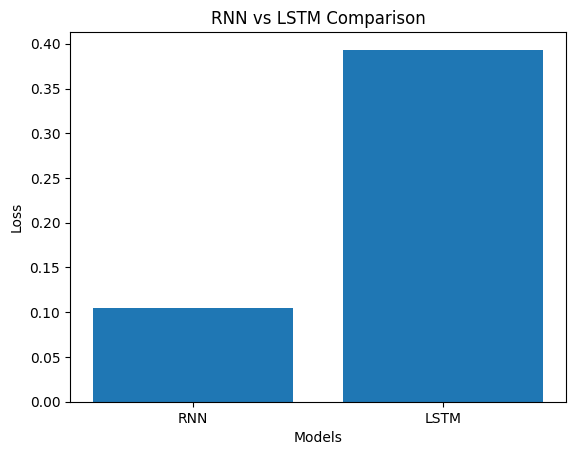

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense

x = np.random.rand(100, 5, 1)
y = np.random.rand(100, 1)

rnn = Sequential()
rnn.add(SimpleRNN(10, input_shape=(5, 1)))
rnn.add(Dense(1))
rnn.compile(optimizer='adam', loss='mse')
rnn.fit(x, y, epochs=5, verbose=0)

lstm = Sequential()
lstm.add(LSTM(10, input_shape=(5, 1)))
lstm.add(Dense(1))
lstm.compile(optimizer='adam', loss='mse')
lstm.fit(x, y, epochs=5, verbose=0)

rnn_loss = rnn.evaluate(x, y, verbose=0)
lstm_loss = lstm.evaluate(x, y, verbose=0)

print("RNN Loss:", rnn_loss)
print("LSTM Loss:", lstm_loss)

plt.bar(["RNN", "LSTM"], [rnn_loss, lstm_loss])
plt.title("RNN vs LSTM Comparison")
plt.xlabel("Models")
plt.ylabel("Loss")
plt.show()

**55. LSTM-Based Stock Price Prediction**

Actual Prices: [115 120 125 130 135 140 145 150 155]
Predicted Prices: [2.1513333 2.1544514 2.1571422 2.1594663 2.1614761 2.1632156 2.164723
 2.166031  2.1671667]


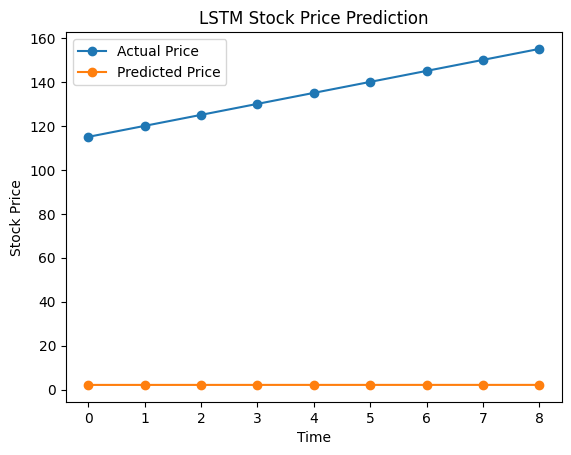

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

prices = np.array([100, 105, 110, 115, 120, 125,
                   130, 135, 140, 145, 150, 155])

x = []
y = []

for i in range(len(prices)-3):
    x.append(prices[i:i+3])
    y.append(prices[i+3])

x = np.array(x).reshape(-1, 3, 1)
y = np.array(y)

model = Sequential()
model.add(LSTM(10, input_shape=(3, 1)))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mse')
model.fit(x, y, epochs=100, verbose=0)

pred = model.predict(x, verbose=0).flatten()

print("Actual Prices:", y)
print("Predicted Prices:", pred)

plt.plot(y, marker='o', label="Actual Price")
plt.plot(pred, marker='o', label="Predicted Price")
plt.title("LSTM Stock Price Prediction")
plt.xlabel("Time")
plt.ylabel("Stock Price")
plt.legend()
plt.show()

**56. GRU-Based Weather Forecasting**

In [8]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense

data = np.array([
    [30, 60, 1010],
    [31, 62, 1012],
    [32, 64, 1011],
    [33, 65, 1013],
    [34, 67, 1014],
    [35, 68, 1015]
])

x = []
y = []

for i in range(len(data)-2):
    x.append(data[i:i+2])
    y.append(data[i+2])

x = np.array(x)
y = np.array(y)

model = Sequential([
    GRU(16, input_shape=(2, 3)),
    Dense(3)
])

model.compile(optimizer='adam', loss='mse')
model.fit(x, y, epochs=100, verbose=0)

test = data[-2:].reshape(1, 2, 3)
prediction = model.predict(test, verbose=0)

print("Predicted Temperature:", round(prediction[0][0], 2))
print("Predicted Humidity:", round(prediction[0][1], 2))
print("Predicted Pressure:", round(prediction[0][2], 2))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Predicted Temperature: -0.11
Predicted Humidity: 2.11
Predicted Pressure: 2.11


**57. Comparison of RNN, LSTM and GRU Models**

SimpleRNN Loss: 0.10141542553901672
LSTM Loss: 0.25050872564315796
GRU Loss: 0.16484452784061432


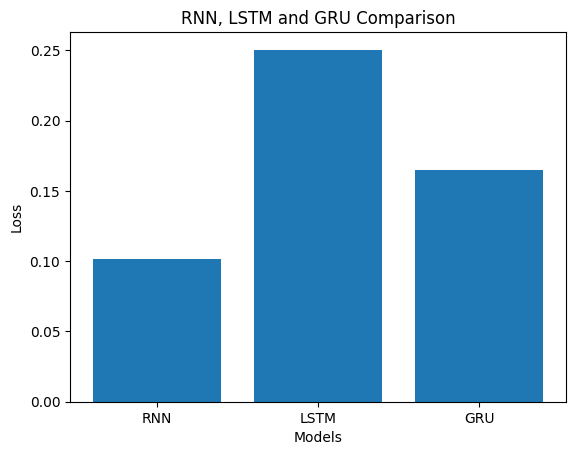

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense

x = np.random.rand(100, 5, 1)
y = np.random.rand(100, 1)

layers = [SimpleRNN, LSTM, GRU]
names = ["RNN", "LSTM", "GRU"]
losses = []

for layer in layers:
    model = Sequential()
    model.add(layer(10, input_shape=(5, 1)))
    model.add(Dense(1))

    model.compile(optimizer='adam', loss='mse')
    model.fit(x, y, epochs=5, verbose=0)

    loss = model.evaluate(x, y, verbose=0)
    losses.append(loss)

    print(layer.__name__, "Loss:", loss)

plt.bar(names, losses)
plt.title("RNN, LSTM and GRU Comparison")
plt.xlabel("Models")
plt.ylabel("Loss")
plt.show()

**58. Stacked RNN for Machine Condition Prediction**

In [10]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

data = np.array([
    [30, 100, 20],
    [32, 105, 22],
    [34, 110, 24],
    [36, 115, 26],
    [38, 120, 28],
    [40, 125, 30]
])

x = []
y = []

for i in range(len(data)-2):
    x.append(data[i:i+2])
    y.append(data[i+2])

x = np.array(x)
y = np.array(y)

model = Sequential([
    SimpleRNN(16, return_sequences=True,
              input_shape=(2, 3)),
    SimpleRNN(8),
    Dense(3)
])

model.compile(optimizer='adam', loss='mse')
model.fit(x, y, epochs=100, verbose=0)

prediction = model.predict(
    data[-2:].reshape(1, 2, 3), verbose=0
)

print("Predicted Machine Condition:")
print(prediction)
print("Stacked RNN Training Completed")

Predicted Machine Condition:
[[1.7231184 1.909944  2.1937256]]
Stacked RNN Training Completed


**59. Vanishing Gradient Problem in RNN**

In [11]:
gradient = 1.0
weight = 0.5

print("Time Step\tGradient")

for i in range(1, 11):
    gradient = gradient * weight
    print(i, "\t\t", round(gradient, 6))

print("Gradient becomes smaller")
print("Vanishing Gradient Problem Demonstrated")

Time Step	Gradient
1 		 0.5
2 		 0.25
3 		 0.125
4 		 0.0625
5 		 0.03125
6 		 0.015625
7 		 0.007812
8 		 0.003906
9 		 0.001953
10 		 0.000977
Gradient becomes smaller
Vanishing Gradient Problem Demonstrated


**60. Effect of Sequence Length on RNN Performance**

Sequence Length: 2 Loss: 0.4054528772830963
Sequence Length: 3 Loss: 0.11415655165910721
Sequence Length: 4 Loss: 1.2699592113494873
Sequence Length: 5 Loss: 0.5363355875015259
Sequence Length: 6 Loss: 0.28907346725463867


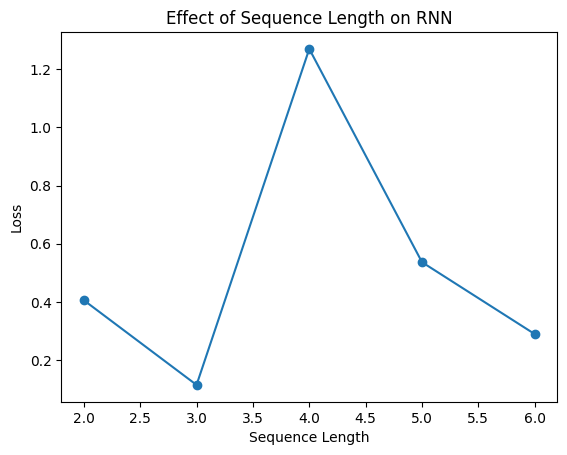

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

sequence_lengths = [2, 3, 4, 5, 6]
losses = []

for length in sequence_lengths:
    x = np.random.rand(100, length, 1)
    y = np.random.rand(100, 1)

    model = Sequential()
    model.add(SimpleRNN(10, input_shape=(length, 1)))
    model.add(Dense(1))

    model.compile(optimizer='adam', loss='mse')
    model.fit(x, y, epochs=5, verbose=0)

    loss = model.evaluate(x, y, verbose=0)
    losses.append(loss)

    print("Sequence Length:", length, "Loss:", loss)

plt.plot(sequence_lengths, losses, marker='o')
plt.title("Effect of Sequence Length on RNN")
plt.xlabel("Sequence Length")
plt.ylabel("Loss")
plt.show()

**61. Hyperparameter Tuning in LSTM**

In [13]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

data = np.array([10, 20, 30, 40, 50,
                 60, 70, 80, 90, 100])

x = []
y = []

for i in range(len(data)-3):
    x.append(data[i:i+3])
    y.append(data[i+3])

x = np.array(x).reshape(-1, 3, 1)
y = np.array(y)

for units in [8, 16]:
    for rate in [0.01, 0.001]:

        model = Sequential([
            LSTM(units, input_shape=(3, 1)),
            Dense(1)
        ])

        model.compile(
            optimizer=__import__('tensorflow').keras.optimizers.Adam(
                learning_rate=rate
            ),
            loss='mse'
        )

        model.fit(x, y, epochs=20,
                  batch_size=2, verbose=0)

        loss = model.evaluate(x, y, verbose=0)

        print("Units:", units)
        print("Learning Rate:", rate)
        print("Loss:", round(loss, 2))

Units: 8
Learning Rate: 0.01
Loss: 4254.42
Units: 8
Learning Rate: 0.001
Loss: 5252.85
Units: 16
Learning Rate: 0.01
Loss: 3692.37
Units: 16
Learning Rate: 0.001
Loss: 5126.73


**62. Evaluation of RNN Using MAE, MSE and RMSE**

MAE: 2.0
MSE: 4.0
RMSE: 2.0


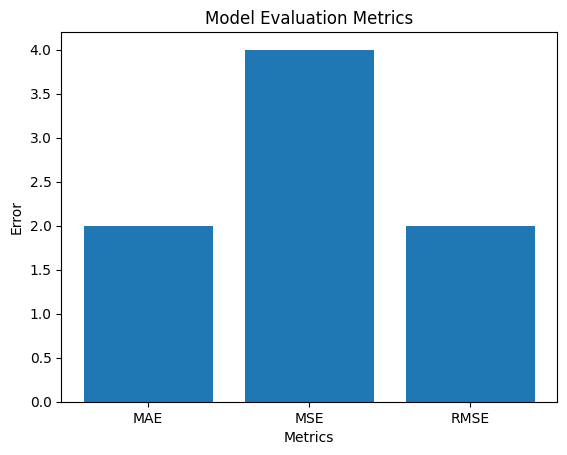

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = np.array([10, 20, 30, 40, 50])
predicted = np.array([12, 18, 32, 38, 48])

mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

plt.bar(["MAE", "MSE", "RMSE"], [mae, mse, rmse])
plt.title("Model Evaluation Metrics")
plt.xlabel("Metrics")
plt.ylabel("Error")
plt.show()

**63. RNN-Based Customer Complaint Classification**

In [15]:
import numpy as np
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

actual = np.array([0, 1, 1, 0, 1, 0])
predicted = np.array([0, 1, 0, 0, 1, 1])

precision = precision_score(actual, predicted)
recall = recall_score(actual, predicted)
f1 = f1_score(actual, predicted)

print("Precision:", round(precision, 2))
print("Recall:", round(recall, 2))
print("F1 Score:", round(f1, 2))

print("Classification Evaluation Completed")

Precision: 0.67
Recall: 0.67
F1 Score: 0.67
Classification Evaluation Completed


**64. Recursive Neural Network for Sentiment Classification**

In [16]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def recursive_network(left, right):
    combined = left + right
    output = sigmoid(combined)
    return output

words = {
    "good": 0.8,
    "bad": -0.8,
    "excellent": 1.0,
    "poor": -1.0
}

left = words["good"]
right = words["excellent"]

result = recursive_network(left, right)

print("Left Word: good")
print("Right Word: excellent")
print("Sentiment Score:", round(result, 2))

if result > 0.5:
    print("Sentiment: Positive")
else:
    print("Sentiment: Negative")

Left Word: good
Right Word: excellent
Sentiment Score: 0.86
Sentiment: Positive
